# 📊 EDA Olist · 10 perguntas para o Raio-X do Vendedor (camada Silver)
**Projeto Hands-On · MBA Data Engineering · Mackenzie**

**Objetivo do projeto:** gerar um **Diagnóstico 360°** para vendedores autônomos, apoiado por um **Radar de Oportunidades** (mercado por categoria e UF) e por um **Termômetro de Envio** (risco de atraso). A pergunta central é: *para um vendedor que quer vender uma categoria a partir do seu estado, qual é o tamanho do mercado, quanto o frete pesa no preço e qual é o risco de o pedido atrasar e gerar avaliação ruim?*

Este EDA lê **direto da camada Silver** (dados já tratados) e responde **10 perguntas** ligadas a essa pergunta central. Cada tópico traz: a **pergunta**, o **uso no projeto**, **o que o código faz**, o **código**, uma linha `✅ RESPOSTA` calculada dos dados e **como interpretar**. Quatro tópicos geram **gráficos prontos para a apresentação** (PNG).

| # | Pergunta | Módulo | Gráfico |
|---|---|---|---|
| 1 | Qual o tamanho do mercado e como ele se distribui por categoria e UF? | Radar | |
| 2 | A oferta de vendedores acompanha a demanda por UF? | Radar | **1** |
| 3 | Quais categorias estão saturadas e quais são oportunidade? | Radar / Diagnóstico | |
| 4 | Quanto o frete pesa no preço do produto? | Diagnóstico (margem) | **2** |
| 5 | O prazo prometido é cumprido e quão raro é o atraso? | Termômetro | |
| 6 | Onde (UF, rota) e quando (mês) o atraso se concentra? | Termômetro / Radar | **3** |
| 7 | Quais sinais conhecidos antes da postagem indicam atraso? | Termômetro | |
| 8 | O atraso derruba a reputação (nota) do vendedor? | Diagnóstico | **4** |
| 9 | O atraso está concentrado em poucos vendedores? | Diagnóstico | |
| 10 | Há massa crítica para benchmark e o que diferencia os melhores lojistas? | Diagnóstico | |

### Guia rápido de leitura
- **Média × mediana:** a mediana é o valor do meio e não é distorcida por extremos; usamos mediana quando há itens muito baratos ou muito caros.
- **Quintil:** divide os dados em 5 grupos de mesmo tamanho (Q1 = 20% menores, Q5 = 20% maiores); mostra se a taxa de atraso sobe ou desce conforme a variável cresce.
- **Taxa de atraso:** % de pedidos entregues depois da data estimada ao cliente.
- **Correlação (−1 a 1):** força da relação entre duas variáveis; perto de 0 = relação fraca. Correlação não é causa.
- **Benchmark:** referência formada pelos melhores lojistas da mesma categoria.

### Silver esperada
O notebook lê as **tabelas já tratadas pelo pipeline Silver do grupo** (uma pasta Parquet por tabela, em `SILVER_PATH`): `orders`, `customers`, `items`, `reviews` (1 avaliação por pedido), `products` (somente com categoria), `sellers`, `translation` e `geolocation`. A tabela `payments` não é usada.

| Tabela Silver | Colunas usadas |
|---|---|
| `olist_orders_dataset` | `order_id`, `customer_id`, `order_status` e as 4 datas (compra, postagem, entrega, estimada) |
| `olist_order_items_dataset` | `order_id`, `order_item_id`, `product_id`, `seller_id`, `price`, `freight_value` |
| `olist_order_reviews_dataset` | `order_id`, `review_score` |
| `olist_customers_dataset` / `olist_sellers_dataset` | UF e prefixo de CEP de comprador e vendedor |
| `olist_products_dataset` / `product_category_name_translation` | categoria (traduzida) e `product_weight_g` |
| `olist_geolocation_dataset` | prefixo de CEP, latitude e longitude |

A seção 0 **constrói a partir delas** as variáveis analíticas (tempos do pedido, atraso, frete sobre preço, rota e distância Haversine) e as tabelas `df_deliv`, `df_m` e `df_md`.

## 0. Importação da Silver e preparação dos gráficos
**O que o código faz:** (1) lê as tabelas Silver (Parquet ou Delta) de `SILVER_PATH`, ou usa `dataframes_silver` se o notebook de tratamento rodou na mesma sessão; (2) valida as colunas obrigatórias e **para com uma lista do que falta**; (3) cria as variáveis analíticas: tempos do pedido (entrega, postagem, transporte, prazo prometido), `is_late`, `frete_pct`, rota e distância de Haversine entre os CEPs; (4) monta `df_deliv` (pedidos entregues), `df_m` (itens) e `df_md` (itens de pedidos entregues), informando quantos itens saem em cada junção; (5) define o estilo dos 4 gráficos e a pasta de saída `IMG_DIR`.

**Ajuste aqui:** `SILVER_PATH` (padrão `/Volumes/workspace/olist_silver/parquet`) e, se quiser, `IMG_DIR`.

In [1]:
import os, warnings
from pyspark.sql import SparkSession, functions as F, Window
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "font.size": 12, "axes.labelsize": 12, "axes.titlesize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Compatibilidade: no Databricks `spark` e `display` já existem; fora dele (Colab/local) criamos equivalentes
if "DATABRICKS_RUNTIME_VERSION" not in os.environ:
    if "spark" not in globals():
        spark = (SparkSession.builder.master("local[4]").appName("olist-eda-silver")
                 .config("spark.driver.memory", "4g").config("spark.sql.shuffle.partitions", "8")
                 .config("spark.sql.ansi.enabled", "false").config("spark.ui.enabled", "false").getOrCreate())
    from IPython.display import display as _d
    def display(obj):
        _d(obj.limit(60).toPandas() if hasattr(obj, "toPandas") else obj)

# >>> AJUSTE AQUI: pasta da Silver (uma subpasta Parquet/Delta por tabela, como gravada no pipeline de tratamento) <<<
SILVER_PATH = os.environ.get("SILVER_PATH", "/Volumes/workspace/olist_silver/parquet")
TABELAS = {"orders": "olist_orders_dataset", "customers": "olist_customers_dataset", "items": "olist_order_items_dataset",
           "reviews": "olist_order_reviews_dataset", "products": "olist_products_dataset", "sellers": "olist_sellers_dataset",
           "translation": "product_category_name_translation", "geolocation": "olist_geolocation_dataset"}

DAY = 86400
pct = lambda cond: F.avg(F.when(cond, 1).otherwise(0)) * 100            # % de linhas que cumprem a condição
bi = lambda v: f"{int(v):,}".replace(",", ".")                           # inteiro com ponto de milhar
br = lambda v, d=1: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")   # número no padrão brasileiro
RESPOSTAS = {}
def resp(n, titulo, texto):
    RESPOSTAS[n] = (titulo, texto)
    print(f"\n✅ RESPOSTA ({n}. {titulo}): {texto}")

def ler(chave):
    tabela = TABELAS[chave]
    if "dataframes_silver" in globals() and tabela in dataframes_silver:    # tratamento rodou nesta mesma sessão
        return dataframes_silver[tabela]
    caminho = f"{SILVER_PATH}/{tabela}"
    try:
        return spark.read.format("delta").load(caminho)
    except Exception:
        try:
            return spark.read.parquet(caminho)
        except Exception as e:
            raise FileNotFoundError(f"Tabela Silver não encontrada em {caminho}. Confira SILVER_PATH e se o tratamento gravou a Silver. Detalhe: {str(e)[:160]}")

orders, customers, items, reviews, products, sellers, translation, geolocation = (ler(k) for k in TABELAS)

# --- contrato: colunas obrigatórias das tabelas Silver ---
REQ = {"orders": (orders, ["order_id", "customer_id", "order_status", "order_purchase_timestamp", "order_delivered_carrier_date",
                           "order_delivered_customer_date", "order_estimated_delivery_date"]),
       "customers": (customers, ["customer_id", "customer_state", "customer_zip_code_prefix"]),
       "items": (items, ["order_id", "order_item_id", "product_id", "seller_id", "price", "freight_value"]),
       "reviews": (reviews, ["order_id", "review_score"]),
       "products": (products, ["product_id", "product_category_name", "product_weight_g"]),
       "sellers": (sellers, ["seller_id", "seller_state", "seller_zip_code_prefix"]),
       "translation": (translation, ["product_category_name", "product_category_name_english"]),
       "geolocation": (geolocation, ["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"])}
chk = pd.DataFrame([(t, c, "✔" if c in df.columns else "✖ FALTA") for t, (df, cols) in REQ.items() for c in cols], columns=["tabela", "coluna", "status"])
if (chk.status != "✔").any():
    display(chk[chk.status != "✔"]); raise ValueError("A Silver não cumpre o contrato: confira as colunas acima.")
print("Contrato da Silver: OK")

# --- tipos (defensivo; a Silver já os padroniza) ---
for c in ["order_purchase_timestamp", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders = orders.withColumn(c, F.col(c).cast("timestamp"))
items = items.withColumn("price", F.col("price").cast("double")).withColumn("freight_value", F.col("freight_value").cast("double"))
zip5 = lambda c: F.lpad(F.regexp_replace(F.trim(F.col(c).cast("string")), r"[^0-9]", ""), 5, "0")
customers = customers.withColumn("customer_zip_code_prefix", zip5("customer_zip_code_prefix"))
sellers = sellers.withColumn("seller_zip_code_prefix", zip5("seller_zip_code_prefix"))
geolocation = (geolocation.withColumn("geolocation_zip_code_prefix", zip5("geolocation_zip_code_prefix"))
               .withColumn("geolocation_lat", F.col("geolocation_lat").cast("double")).withColumn("geolocation_lng", F.col("geolocation_lng").cast("double")))
products = products.withColumn("product_weight_g", F.col("product_weight_g").cast("double"))

# --- pedidos: tempos, atraso e nota (a Silver mantém 1 avaliação por pedido) ---
ts = F.unix_timestamp
orders = (orders
    .withColumn("is_delivered", ((F.col("order_status") == "delivered") & F.col("order_delivered_customer_date").isNotNull()).cast("int"))
    .withColumn("delivery_time_days", (ts("order_delivered_customer_date") - ts("order_purchase_timestamp")) / DAY)
    .withColumn("delivery_delay_days", (ts("order_delivered_customer_date") - ts("order_estimated_delivery_date")) / DAY)
    .withColumn("handling_time_days", (ts("order_delivered_carrier_date") - ts("order_purchase_timestamp")) / DAY)
    .withColumn("carrier_time_days", (ts("order_delivered_customer_date") - ts("order_delivered_carrier_date")) / DAY)
    .withColumn("estimated_lead_days", (ts("order_estimated_delivery_date") - ts("order_purchase_timestamp")) / DAY)
    .withColumn("purchase_month", F.date_format("order_purchase_timestamp", "yyyy-MM"))
    .withColumn("is_late", F.when(F.col("is_delivered") == 1, (F.col("order_delivered_customer_date") > F.col("order_estimated_delivery_date")).cast("double")))
    .join(reviews.select("order_id", "review_score").withColumn("review_score", F.col("review_score").cast("double")), "order_id", "left"))
ORDER_COLS = ["order_id", "customer_id", "order_status", "is_delivered", "is_late", "delivery_time_days", "delivery_delay_days", "handling_time_days",
              "carrier_time_days", "estimated_lead_days", "purchase_month", "review_score"]

# --- geolocalização: 1 coordenada por CEP (mediana), descartando pontos fora do Brasil ---
geo_p = (geolocation.filter(F.col("geolocation_lat").between(-34, 6) & F.col("geolocation_lng").between(-74, -34))
         .groupBy(F.col("geolocation_zip_code_prefix").alias("zip"))
         .agg(F.expr("percentile_approx(geolocation_lat, 0.5)").alias("lat"), F.expr("percentile_approx(geolocation_lng, 0.5)").alias("lng")))

def haversine_km(lat1, lon1, lat2, lon2, R=6371.0088):
    lat1, lon1, lat2, lon2 = [F.col(c) if isinstance(c, str) else c for c in (lat1, lon1, lat2, lon2)]
    p1, p2 = F.radians(lat1), F.radians(lat2)
    a = F.sin((p2 - p1) / 2) ** 2 + F.cos(p1) * F.cos(p2) * F.sin(F.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * F.asin(F.sqrt(a))

# --- categoria em inglês e tabela de itens enriquecida (1 linha por item) ---
prod = (products.join(translation, "product_category_name", "left")
        .withColumn("category", F.coalesce("product_category_name_english", "product_category_name")))
n_itens = items.count()
com_pedido = items.join(orders.select(*ORDER_COLS), "order_id", "inner")                      # descarta itens de pedidos removidos na Silver
n_pedido = com_pedido.count()
df_m = (com_pedido
    .join(customers.select("customer_id", "customer_state", F.col("customer_zip_code_prefix").alias("c_zip")), "customer_id", "inner")
    .join(sellers.select("seller_id", "seller_state", F.col("seller_zip_code_prefix").alias("s_zip")), "seller_id", "left")
    .join(prod.select("product_id", "category", "product_weight_g"), "product_id", "inner")      # descarta itens de produtos sem categoria (removidos na Silver)
    .join(geo_p.select(F.col("zip").alias("c_zip"), F.col("lat").alias("c_lat"), F.col("lng").alias("c_lng")), "c_zip", "left")
    .join(geo_p.select(F.col("zip").alias("s_zip"), F.col("lat").alias("s_lat"), F.col("lng").alias("s_lng")), "s_zip", "left")
    .withColumn("freight_ratio", F.when(F.col("price") > 0, F.col("freight_value") / F.col("price")))
    .withColumn("frete_pct", F.col("freight_ratio") * 100)
    .withColumn("route", F.concat_ws(" → ", "seller_state", "customer_state"))
    .withColumn("same_state", (F.col("seller_state") == F.col("customer_state")).cast("int"))
    .withColumn("distance_km", haversine_km("s_lat", "s_lng", "c_lat", "c_lng"))
    .cache())
n_final = df_m.count()
print(f"Itens na Silver: {n_itens:,} → com pedido válido: {n_pedido:,} → com produto/categoria: {n_final:,} ({n_itens - n_final:,} itens fora da análise)")

df_deliv = orders.filter(F.col("is_delivered") == 1).cache()     # 1 linha por pedido entregue
df_dr = df_deliv.filter(F.col("review_score").isNotNull())       # ... com avaliação
df_md = df_m.filter(F.col("is_delivered") == 1)                  # itens de pedidos entregues
per = df_deliv.agg(F.min("order_purchase_timestamp"), F.max("order_purchase_timestamp")).first()
print(f"Pedidos Silver: {orders.count():,} | entregues: {df_deliv.count():,} | itens entregues analisados: {df_md.count():,} | "
      f"distância calculada em {df_md.agg(pct(F.col('distance_km').isNotNull())).first()[0]:.1f}% dos itens | período: {per[0]:%m/%Y} a {per[1]:%m/%Y}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/13 22:49:22 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/13 22:49:22 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 22:49:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Contrato da Silver: OK


26/11/13 22:49:43 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Itens na Silver: 112,650 → com pedido válido: 112,642 → com produto/categoria: 111,039 (1,611 itens fora da análise)


Pedidos Silver: 99,433 | entregues: 96,470 | itens entregues analisados: 108,652 | distância calculada em 99.5% dos itens | período: 09/2016 a 08/2018


In [2]:
# ---------- Estilo dos gráficos da apresentação e exportação ----------
import json
IMG_DIR = os.environ.get("IMG_DIR", "img")        # no Databricks, prefira um Volume: /Volumes/<catalogo>/<schema>/<volume>/img
os.makedirs(IMG_DIR, exist_ok=True)
COR = {"azul": "#1f4e79", "laranja": "#e07a5f", "verde": "#3d8f6b", "cinza": "#8d99ae", "claro": "#a8c5da", "texto": "#1b263b"}
FONTE = "Fonte: Olist Brazilian E-Commerce (Kaggle), 2016–2018 · camada Silver · Projeto Hands-On, MBA Data Engineering"
GRAFICOS, KPIS = {}, {}
kp = lambda nome, v: KPIS.__setitem__(nome, float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v)

def estilo_ax(ax):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.spines["left"].set_color("#ced4da"); ax.spines["bottom"].set_color("#ced4da")
    ax.tick_params(colors=COR["texto"]); ax.grid(False); ax.grid(axis="y", color="#e9ecef"); ax.set_axisbelow(True)

import textwrap
def salvar_grafico(fig, arquivo, titulo, subtitulo, modulo, bottom=0.14):
    subtitulo = "\n".join(textwrap.wrap(subtitulo, 118))
    fig.subplots_adjust(top=0.80 - 0.035 * subtitulo.count("\n"), bottom=bottom, left=0.08, right=0.97)
    fig.text(0.01, 0.95, titulo, fontsize=17, fontweight="bold", color=COR["texto"], ha="left", va="top")
    fig.text(0.01, 0.885, subtitulo, fontsize=10.5, color="#495057", ha="left", va="top", linespacing=1.4)
    fig.text(0.01, 0.015, FONTE, fontsize=8, color="#6c757d", ha="left")
    caminho = f"{IMG_DIR}/{arquivo}.png"
    fig.savefig(caminho, dpi=200, facecolor="white")
    GRAFICOS[arquivo] = {"arquivo": f"{arquivo}.png", "titulo": titulo, "subtitulo": subtitulo.replace("\n", " "), "modulo": modulo}
    plt.show(); print(f"Gráfico salvo em: {caminho}")

## 1. Tamanho do mercado
**Pergunta:** Qual o tamanho do mercado analisado e como ele se distribui entre categorias e estados?

**Uso no projeto:** Radar de Oportunidades: dimensiona a demanda que o vendedor pode disputar (o 'tamanho do mercado' da pergunta central).

**O que o código faz:**
- Soma pedidos, itens, receita (soma de `price`), vendedores, categorias e UFs compradoras dos pedidos entregues.
- Ranqueia as 10 maiores categorias por receita e as 10 maiores UFs por pedidos.
- Calcula a participação e a participação acumulada de cada uma.

In [3]:
# ===== 1. TAMANHO DO MERCADO =====
mkt = df_md.agg(F.countDistinct("order_id").alias("pedidos"), F.count("*").alias("itens"), F.round(F.sum("price"), 0).alias("receita_rs"),
                F.round(F.avg("price"), 2).alias("preco_medio_rs"), F.countDistinct("seller_id").alias("vendedores"),
                F.countDistinct("category").alias("categorias"), F.countDistinct("customer_state").alias("ufs_compradoras"))
display(mkt)
m = mkt.first()
cat = (df_md.filter(F.col("category") != "unknown").groupBy("category")
       .agg(F.countDistinct("order_id").alias("pedidos"), F.round(F.sum("price"), 0).alias("receita_rs"), F.countDistinct("seller_id").alias("vendedores")).toPandas()
       .sort_values("receita_rs", ascending=False))
cat["pct_receita"] = cat.receita_rs / m["receita_rs"] * 100
cat["pct_acumulada"] = cat.pct_receita.cumsum()
print("--- 10 maiores categorias por receita ---"); display(cat.head(10).reset_index(drop=True))
ufd = (df_md.groupBy("customer_state").agg(F.countDistinct("order_id").alias("pedidos"), F.round(F.sum("price"), 0).alias("receita_rs")).toPandas()
       .sort_values("pedidos", ascending=False))
ufd["pct_pedidos"] = ufd.pedidos / ufd.pedidos.sum() * 100
ufd["pct_acumulada"] = ufd.pct_pedidos.cumsum()
print("--- 10 maiores UFs por pedidos ---"); display(ufd.head(10).reset_index(drop=True))
t10c, t3u = cat.pct_receita.head(10).sum(), ufd.pct_pedidos.head(3).sum()
for k, v in {"pedidos_entregues": m["pedidos"], "itens_entregues": m["itens"], "receita_rs": m["receita_rs"], "vendedores_ativos": m["vendedores"],
             "categorias": m["categorias"], "top10_categorias_pct_receita": t10c, "top3_uf_pct_pedidos": t3u}.items(): kp(k, v)
resp(1, "Tamanho do mercado",
     f"O mercado analisado soma {bi(m['pedidos'])} pedidos entregues, R$ {bi(m['receita_rs'])} em receita e {bi(m['vendedores'])} vendedores ativos em {m['categorias']} categorias. "
     f"As 10 maiores categorias respondem por {br(t10c)}% da receita (líder: {cat.category.iloc[0]}, {br(cat.pct_receita.iloc[0])}%) e as 3 maiores UFs ({', '.join(ufd.customer_state.head(3))}) por {br(t3u)}% dos pedidos.")

,pedidos,itens,receita_rs,preco_medio_rs,vendedores,categorias,ufs_compradoras
0,95138,108652,"13,049,522.00",120.10,2914,73,27


--- 10 maiores categorias por receita ---


,category,pedidos,receita_rs,vendedores,pct_receita,pct_acumulada
0,health_beauty,8647,"1,233,132.00",479,9.45,9.45
1,watches_gifts,5493,"1,165,899.00",95,8.93,18.38
2,bed_bath_table,9272,"1,023,435.00",189,7.84,26.23
3,sports_leisure,7529,"954,674.00",466,7.32,33.54
4,computers_accessories,6529,"888,614.00",279,6.81,40.35
5,furniture_decor,6307,"711,928.00",352,5.46,45.81
6,housewares,5743,"615,629.00",452,4.72,50.53
7,cool_stuff,3559,"610,204.00",259,4.68,55.20
8,auto,3809,"578,849.00",371,4.44,59.64
9,toys,3803,"471,097.00",242,3.61,63.25


--- 10 maiores UFs por pedidos ---


,customer_state,pedidos,receita_rs,pct_pedidos,pct_acumulada
0,SP,39956,"5,003,682.00",42.00,42.00
1,RJ,12168,"1,736,925.00",12.79,54.79
2,MG,11190,"1,534,496.00",11.76,66.55
3,RS,5269,"720,823.00",5.54,72.09
4,PR,4855,"657,744.00",5.10,77.19
5,SC,3491,"500,030.00",3.67,80.86
6,BA,3215,"487,660.00",3.38,84.24
7,DF,2050,"293,920.00",2.15,86.39
8,ES,1978,"267,029.00",2.08,88.47
9,GO,1911,"274,307.00",2.01,90.48



✅ RESPOSTA (1. Tamanho do mercado): O mercado analisado soma 95.138 pedidos entregues, R$ 13.049.522 em receita e 2.914 vendedores ativos em 73 categorias. As 10 maiores categorias respondem por 63,2% da receita (líder: health_beauty, 9,4%) e as 3 maiores UFs (SP, RJ, MG) por 66,5% dos pedidos.


**Como interpretar**
- Compare `pct_receita` e `pct_acumulada`: quando poucas categorias somam a maior parte da receita, o mercado é concentrado e a escolha da categoria pesa muito.
- Uma UF com grande `pct_pedidos` é um destino de grande demanda, mas isso só vira oportunidade se o custo logístico para chegar lá for viável (veja as perguntas 6 e 7).
- `preco_medio_rs` baixo indica que o frete tende a pesar mais (pergunta 4).

## 2. Oferta × demanda por UF
**Pergunta:** A oferta de vendedores acompanha a demanda de cada estado?

**Uso no projeto:** Radar de Oportunidades: identifica onde há muita demanda e pouca oferta local, base do mapa de calor e da análise de saturação.

**O que o código faz:**
- **Demanda:** pedidos por UF do comprador. **Oferta:** pedidos vendidos por vendedores de cada UF e número de vendedores locais.
- Calcula a participação de cada UF nas duas pontas e os pedidos por vendedor local.
- **Gera o Gráfico 1** (demanda × oferta das maiores UFs).

,pedidos,vendedores,pedidos_vendidos,uf,pct_demanda,pct_oferta,pedidos_por_vendedor_local
0,39956,1735,67663,SP,42.00,70.75,23.03
1,12168,161,4151,RJ,12.79,4.34,75.58
2,11190,227,7566,MG,11.76,7.91,49.30
3,5269,124,1923,RS,5.54,2.01,42.49
4,4855,331,7465,PR,5.10,7.81,14.67
5,3491,180,3586,SC,3.67,3.75,19.39
6,3215,18,550,BA,3.38,0.58,178.61
7,2050,30,799,DF,2.15,0.84,68.33
8,1978,22,304,ES,2.08,0.32,89.91
9,1911,37,442,GO,2.01,0.46,51.65


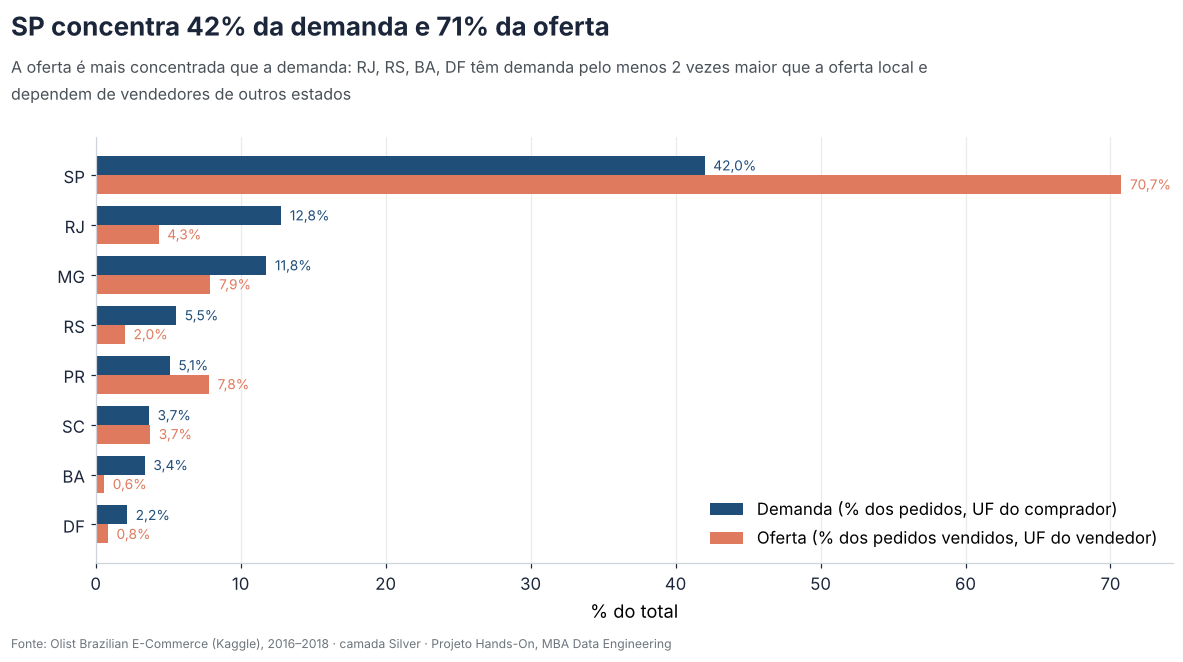

Gráfico salvo em: /home/claude/eda/img/grafico1_demanda_oferta.png

✅ RESPOSTA (2. Oferta × demanda por UF): SP tem 42,0% da demanda e 70,7% da oferta. UFs com muita demanda e poucos vendedores locais: BA (179 pedidos por vendedor local), PE (175 pedidos por vendedor local), CE (106 pedidos por vendedor local). 5 UFs não têm nenhum vendedor com entregas na base.


In [4]:
# ===== 2. OFERTA × DEMANDA POR UF =====
dem = df_md.groupBy("customer_state").agg(F.countDistinct("order_id").alias("pedidos"))
sup = df_md.groupBy("seller_state").agg(F.countDistinct("seller_id").alias("vendedores"), F.countDistinct("order_id").alias("pedidos_vendidos"))
gm = (dem.join(sup, dem.customer_state == sup.seller_state, "full_outer").withColumn("uf", F.coalesce("customer_state", "seller_state"))
        .drop("customer_state", "seller_state").fillna(0).toPandas().sort_values("pedidos", ascending=False))
gm["pct_demanda"] = gm.pedidos / gm.pedidos.sum() * 100
gm["pct_oferta"] = gm.pedidos_vendidos / gm.pedidos_vendidos.sum() * 100
gm["pedidos_por_vendedor_local"] = gm.pedidos / gm.vendedores.replace(0, np.nan)
display(gm.head(12).round(2).reset_index(drop=True))

# ---- GRÁFICO 1: demanda × oferta ----
g = gm.head(8).iloc[::-1]; y = np.arange(len(g)); h = 0.38
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.barh(y + h / 2, g.pct_demanda, h, color=COR["azul"], label="Demanda (% dos pedidos, UF do comprador)")
ax.barh(y - h / 2, g.pct_oferta, h, color=COR["laranja"], label="Oferta (% dos pedidos vendidos, UF do vendedor)")
for yi, d_, o_ in zip(y, g.pct_demanda, g.pct_oferta):
    ax.text(d_ + .6, yi + h / 2, f"{br(d_)}%", va="center", fontsize=9, color=COR["azul"]); ax.text(o_ + .6, yi - h / 2, f"{br(o_)}%", va="center", fontsize=9, color=COR["laranja"])
ax.set_yticks(y); ax.set_yticklabels(g.uf, fontsize=11); ax.set_xlabel("% do total"); ax.legend(frameon=False, loc="lower right"); estilo_ax(ax); ax.grid(axis="x", color="#e9ecef"); ax.grid(axis="y", visible=False)
sp = gm.set_index("uf").loc["SP"]
deficit = [u_ for u_, d_, o_ in zip(g.uf.iloc[::-1], g.pct_demanda.iloc[::-1], g.pct_oferta.iloc[::-1]) if o_ > 0 and d_ / o_ >= 2]
salvar_grafico(fig, "grafico1_demanda_oferta", f"SP concentra {br(sp.pct_demanda, 0)}% da demanda e {br(sp.pct_oferta, 0)}% da oferta",
               f"A oferta é mais concentrada que a demanda: {', '.join(deficit)} têm demanda pelo menos 2 vezes maior que a oferta local e dependem de vendedores de outros estados", "Radar de Oportunidades")

sub = gm[(gm.pedidos >= 1000) & (gm.vendedores > 0)].sort_values("pedidos_por_vendedor_local", ascending=False).head(3)
for k, v in {"sp_pct_demanda": sp.pct_demanda, "sp_pct_oferta": sp.pct_oferta, "ufs_sem_vendedor": (gm.vendedores == 0).sum()}.items(): kp(k, v)
resp(2, "Oferta × demanda por UF",
     f"SP tem {br(sp.pct_demanda)}% da demanda e {br(sp.pct_oferta)}% da oferta. UFs com muita demanda e poucos vendedores locais: " +
     ", ".join(f"{r.uf} ({br(r.pedidos_por_vendedor_local, 0)} pedidos por vendedor local)" for r in sub.itertuples()) + f". {(gm.vendedores == 0).sum()} UFs não têm nenhum vendedor com entregas na base.")

**Como interpretar**
- **Barra laranja menor que a azul** em uma UF = demanda pouco atendida localmente (possível oportunidade, mas o vendedor de fora paga mais frete e leva mais tempo).
- **Barra laranja maior que a azul** (SP) = UF exportadora: seus vendedores atendem o país todo.
- `pedidos_por_vendedor_local` alto sinaliza pouca concorrência local, não necessariamente mercado fácil: confira prazo e atraso do destino na pergunta 6.

## 3. Saturação por categoria
**Pergunta:** Quais categorias têm muita demanda para poucos vendedores (oportunidade) e quais estão saturadas?

**Uso no projeto:** Radar de Oportunidades (análise de saturação) e Diagnóstico 360° (contexto competitivo da categoria do vendedor).

**O que o código faz:**
- Para cada categoria com pelo menos 300 pedidos, conta pedidos e vendedores ativos e calcula **pedidos por vendedor**.
- Mostra as mais saturadas (poucos pedidos por vendedor) e as mais oportunas (muitos pedidos por vendedor).

In [5]:
# ===== 3. SATURAÇÃO POR CATEGORIA =====
sat = (df_md.filter(F.col("category") != "unknown").groupBy("category")
       .agg(F.countDistinct("order_id").alias("pedidos"), F.countDistinct("seller_id").alias("vendedores"), F.round(F.sum("price"), 0).alias("receita_rs"))
       .withColumn("pedidos_por_vendedor", F.round(F.col("pedidos") / F.col("vendedores"), 2)).filter("pedidos >= 300").toPandas().sort_values("pedidos_por_vendedor"))
print(f"Categorias analisadas (300+ pedidos): {len(sat)}")
print("Mais saturadas:"); display(sat.head(8).reset_index(drop=True))
print("Mais oportunas:"); display(sat.tail(8).iloc[::-1].reset_index(drop=True))
s3, o3 = sat.head(3), sat.tail(3).iloc[::-1]
resp(3, "Saturação por categoria",
     "Mais saturadas (poucos pedidos por vendedor): " + ", ".join(f"{r.category} ({br(r.pedidos_por_vendedor)})" for r in s3.itertuples()) +
     ". Mais oportunas (muitos pedidos por vendedor): " + ", ".join(f"{r.category} ({br(r.pedidos_por_vendedor)})" for r in o3.itertuples()) + ".")

Categorias analisadas (300+ pedidos): 31
Mais saturadas:


,category,pedidos,vendedores,receita_rs,pedidos_por_vendedor
0,construction_tools_construction,736,123,"142,108.00",5.98
1,small_appliances,609,97,"182,754.00",6.28
2,home_construction,483,67,"81,408.00",7.21
3,furniture_living_room,414,55,"67,351.00",7.53
4,food,441,56,"28,731.00",7.88
5,musical_instruments,611,67,"184,316.00",9.12
6,books_general_interest,495,53,"45,256.00",9.34
7,audio,348,36,"50,571.00",9.67


Mais oportunas:


,category,pedidos,vendedores,receita_rs,pedidos_por_vendedor
0,watches_gifts,5493,95,"1,165,899.00",57.82
1,bed_bath_table,9272,189,"1,023,435.00",49.06
2,office_furniture,1254,30,"268,154.00",41.80
3,telephony,4093,142,"309,860.00",28.82
4,computers_accessories,6529,279,"888,614.00",23.40
5,home_confort,392,20,"58,008.00",19.60
6,fashion_bags_accessories,1820,97,"149,329.00",18.76
7,health_beauty,8647,479,"1,233,132.00",18.05



✅ RESPOSTA (3. Saturação por categoria): Mais saturadas (poucos pedidos por vendedor): construction_tools_construction (6,0), small_appliances (6,3), home_construction (7,2). Mais oportunas (muitos pedidos por vendedor): watches_gifts (57,8), bed_bath_table (49,1), office_furniture (41,8).


**Como interpretar**
- **Pedidos por vendedor baixo** = muitos vendedores dividindo pouca demanda (saturação); **alto** = poucos vendedores concentram a demanda.
- Uma categoria oportuna pode ter barreiras (frete pesado, logística complexa): cruze com as perguntas 4 e 6 antes de recomendar.
- A medida considera só vendedores que venderam na base; não mede concorrência fora dela.

## 4. Peso do frete no preço
**Pergunta:** Quanto o frete pesa no preço do produto e o que explica o valor do frete?

**Uso no projeto:** Diagnóstico 360° (margem e dimensão frete/preço) e alerta ao vendedor sobre itens em que o frete compromete a venda.

**O que o código faz:**
- Divide os itens em 6 faixas de preço e calcula, em cada uma, o **frete ÷ preço** (mediana, percentil 90) e a % de itens com frete de 30% ou mais do preço.
- Calcula a correlação do frete com peso, distância e preço.
- **Gera o Gráfico 2** (frete sobre preço por faixa de preço).

,faixa_preco,itens,frete_mediano_rs,mediana_frete_pct,p90_frete_pct,pct_itens_frete_ge_30
0,≤ R$ 25,13586,14.10,73.20,141.10,97.40
1,R$ 25–50,25074,15.10,37.70,62.00,70.90
2,R$ 50–100,32709,16.18,22.30,38.30,20.60
3,R$ 100–200,26427,18.61,13.60,28.90,9.30
4,R$ 200–500,10056,20.99,7.70,20.70,3.70
5,> R$ 500,3187,31.23,3.80,11.50,0.80


Correlação (Pearson) do valor do frete com: peso 0.61 | distância 0.39 | preço 0.41


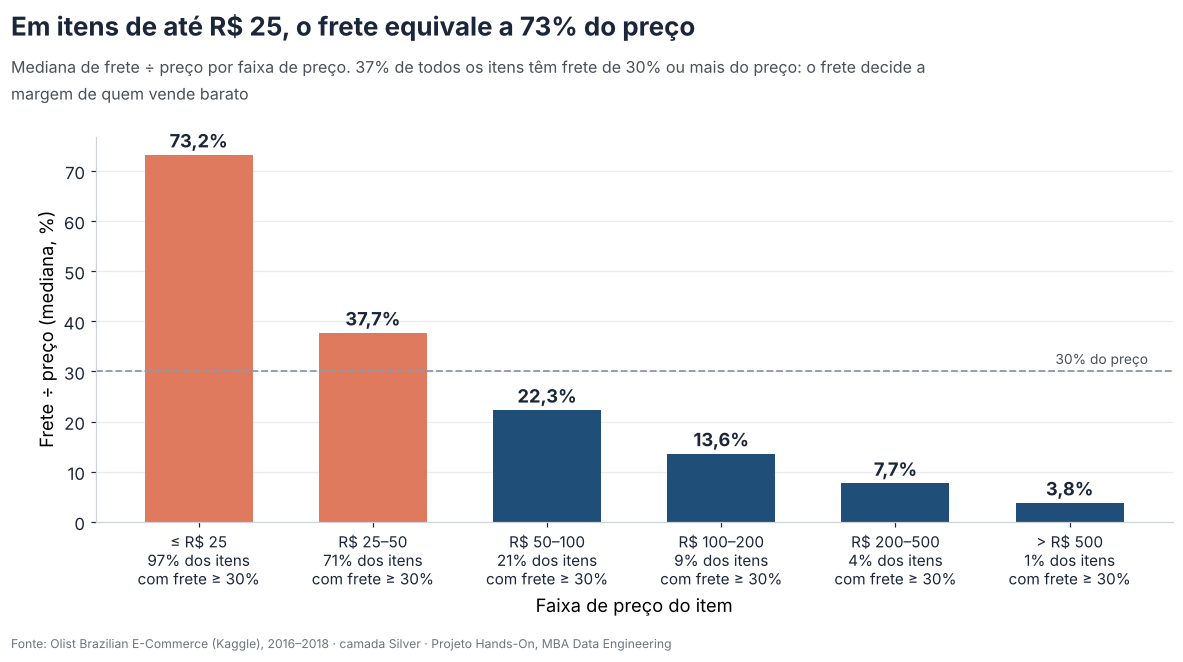

Gráfico salvo em: /home/claude/eda/img/grafico2_frete_preco.png

✅ RESPOSTA (4. Peso do frete no preço): O frete pesa mais quanto mais barato o item: a mediana é 73,2% do preço até R$ 25, 37,7% entre R$ 25 e 50 e 3,8% acima de R$ 500; 36,6% de todos os itens têm frete igual ou maior que 30% do preço. O frete acompanha o peso (correlação 0,61), o preço (0,41) e a distância (0,39).


In [6]:
# ===== 4. PESO DO FRETE NO PREÇO =====
fp = (F.when(F.col("price") <= 25, "≤ R$ 25").when(F.col("price") <= 50, "R$ 25–50").when(F.col("price") <= 100, "R$ 50–100")
       .when(F.col("price") <= 200, "R$ 100–200").when(F.col("price") <= 500, "R$ 200–500").otherwise("> R$ 500"))
ordem = ["≤ R$ 25", "R$ 25–50", "R$ 50–100", "R$ 100–200", "R$ 200–500", "> R$ 500"]
t4 = (df_m.groupBy(fp.alias("faixa_preco")).agg(F.count("*").alias("itens"), F.round(F.expr("percentile_approx(freight_value, 0.5)"), 2).alias("frete_mediano_rs"),
      F.round(F.expr("percentile_approx(frete_pct, 0.5)"), 1).alias("mediana_frete_pct"), F.round(F.expr("percentile_approx(frete_pct, 0.9)"), 1).alias("p90_frete_pct"),
      F.round(pct(F.col("frete_pct") >= 30), 1).alias("pct_itens_frete_ge_30")).toPandas().set_index("faixa_preco").loc[ordem].reset_index())
display(t4)
dd = df_md.filter(F.col("distance_km").isNotNull() & F.col("product_weight_g").isNotNull())
cw, cd_, cp = dd.stat.corr("freight_value", "product_weight_g"), dd.stat.corr("freight_value", "distance_km"), dd.stat.corr("freight_value", "price")
print(f"Correlação (Pearson) do valor do frete com: peso {cw:.2f} | distância {cd_:.2f} | preço {cp:.2f}")
g30 = df_m.agg(pct(F.col("frete_pct") >= 30)).first()[0]

# ---- GRÁFICO 2: frete sobre preço por faixa ----
fig, ax = plt.subplots(figsize=(11, 6.2))
cores = [COR["laranja"] if v >= 30 else COR["azul"] for v in t4.mediana_frete_pct]
b = ax.bar(t4.faixa_preco, t4.mediana_frete_pct, color=cores, width=.62)
for rect, v, p in zip(b, t4.mediana_frete_pct, t4.pct_itens_frete_ge_30):
    ax.text(rect.get_x() + rect.get_width() / 2, v + 1.5, f"{br(v)}%", ha="center", fontsize=12, fontweight="bold", color=COR["texto"])
ax.axhline(30, color=COR["cinza"], ls="--", lw=1.2); ax.text(5.45, 31.5, "30% do preço", ha="right", fontsize=9, color="#495057")
ax.set_xticks(range(len(t4))); ax.set_xticklabels([f"{f_}\n{br(p_, 0)}% dos itens\ncom frete ≥ 30%" for f_, p_ in zip(t4.faixa_preco, t4.pct_itens_frete_ge_30)], fontsize=10)
ax.set_ylabel("Frete ÷ preço (mediana, %)"); ax.set_xlabel("Faixa de preço do item"); estilo_ax(ax)
salvar_grafico(fig, "grafico2_frete_preco", f"Em itens de até R$ 25, o frete equivale a {br(t4.mediana_frete_pct.iloc[0], 0)}% do preço",
               f"Mediana de frete ÷ preço por faixa de preço. {br(g30, 0)}% de todos os itens têm frete de 30% ou mais do preço: o frete decide a margem de quem vende barato", "Diagnóstico 360° · margem", bottom=0.2)
for k, v in {"frete_pct_mediano_ate25": t4.mediana_frete_pct.iloc[0], "frete_pct_mediano_acima500": t4.mediana_frete_pct.iloc[-1], "pct_itens_frete_ge30": g30,
             "pct_itens_ate25_frete_ge30": t4.pct_itens_frete_ge_30.iloc[0], "corr_frete_peso": cw, "corr_frete_distancia": cd_, "corr_frete_preco": cp}.items(): kp(k, v)
resp(4, "Peso do frete no preço",
     f"O frete pesa mais quanto mais barato o item: a mediana é {br(t4.mediana_frete_pct.iloc[0])}% do preço até R$ 25, {br(t4.mediana_frete_pct.iloc[1])}% entre R$ 25 e 50 e {br(t4.mediana_frete_pct.iloc[-1])}% acima de R$ 500; "
     f"{br(g30)}% de todos os itens têm frete igual ou maior que 30% do preço. O frete acompanha o peso (correlação {br(cw, 2)}), o preço ({br(cp, 2)}) e a distância ({br(cd_, 2)}).")

**Como interpretar**
- **Barras laranja** passam de 30% do preço: nessas faixas, o frete é um problema de margem e de competitividade do anúncio.
- Use a **mediana** (e não a média): itens baratos com frete maior que o preço puxam a média para cima.
- O frete depende mais de **peso** do que de distância ou preço (correlações acima): produtos leves e baratos são os mais sensíveis; para o vendedor, embalagem e peso são alavancas.

## 5. Prazo prometido × entregue
**Pergunta:** O prazo prometido ao cliente é cumprido? Quão raro é o atraso e quão grande ele é quando ocorre?

**Uso no projeto:** Termômetro de Envio: define a taxa de base do evento 'atraso' (alvo do modelo) e o tamanho do problema.

**O que o código faz:**
- Mede, nos pedidos entregues, a taxa de atraso (entrega depois da data estimada), o tempo de entrega (média, mediana, P90), o prazo prometido e a **folga** (prazo prometido − tempo real).
- Calcula o atraso médio dos pedidos que atrasam e a % de entregas acima de 15 dias.

In [7]:
# ===== 5. PRAZO PROMETIDO × ENTREGUE =====
t5 = df_deliv.agg(
    F.count("*").alias("pedidos_entregues"), F.round(F.avg("is_late") * 100, 2).alias("taxa_atraso_pct"),
    F.round(F.avg("delivery_time_days"), 2).alias("entrega_media_dias"), F.round(F.expr("percentile_approx(delivery_time_days, 0.5)"), 2).alias("entrega_mediana"),
    F.round(F.expr("percentile_approx(delivery_time_days, 0.9)"), 2).alias("entrega_p90"), F.round(F.avg("estimated_lead_days"), 2).alias("prazo_prometido_medio"),
    F.round(-F.avg("delivery_delay_days"), 2).alias("folga_media_dias"),
    F.round(F.avg(F.when(F.col("is_late") == 1, F.col("delivery_delay_days"))), 2).alias("atraso_medio_quando_atrasa"),
    F.round(pct(F.col("delivery_time_days") > 15), 1).alias("pct_entrega_gt_15d"))
display(t5)
x = t5.first()
for k, v in {"taxa_atraso_pct": x["taxa_atraso_pct"], "entrega_media_dias": x["entrega_media_dias"], "prazo_prometido_medio": x["prazo_prometido_medio"],
             "folga_media_dias": x["folga_media_dias"], "atraso_medio_quando_atrasa": x["atraso_medio_quando_atrasa"]}.items(): kp(k, v)
resp(5, "Prazo prometido × entregue",
     f"{br(x['taxa_atraso_pct'], 2)}% dos pedidos entregues chegam depois do prazo. A entrega leva em média {br(x['entrega_media_dias'])} dias (mediana {br(x['entrega_mediana'])}; 90% até {br(x['entrega_p90'])}) contra "
     f"{br(x['prazo_prometido_medio'])} prometidos, folga média de {br(x['folga_media_dias'])} dias. Quando atrasa, o atraso médio é de {br(x['atraso_medio_quando_atrasa'])} dias. O atraso é um evento raro e de impacto grande.")

,pedidos_entregues,taxa_atraso_pct,entrega_media_dias,entrega_mediana,entrega_p90,prazo_prometido_medio,folga_media_dias,atraso_medio_quando_atrasa,pct_entrega_gt_15d
0,96470,8.11,12.56,10.22,23.09,23.74,11.18,9.55,27.30



✅ RESPOSTA (5. Prazo prometido × entregue): 8,11% dos pedidos entregues chegam depois do prazo. A entrega leva em média 12,6 dias (mediana 10,2; 90% até 23,1) contra 23,7 prometidos, folga média de 11,2 dias. Quando atrasa, o atraso médio é de 9,6 dias. O atraso é um evento raro e de impacto grande.


**Como interpretar**
- **Folga média alta + taxa de atraso baixa**: as operações embutem uma gordura no prazo; na média o cliente recebe bem antes do prometido.
- Mesmo assim, o atraso que ocorre é longo (veja `atraso_medio_quando_atrasa`): o problema é a **cauda**, não a média.
- Como o atraso é raro, o modelo preditivo lida com **classes desbalanceadas**: avalie por PR-AUC e recall, nunca só por acurácia.

## 6. Onde e quando o atraso se concentra
**Pergunta:** Quais estados, rotas e meses concentram os atrasos?

**Uso no projeto:** Termômetro de Envio (a rota e o calendário são as variáveis centrais do aviso 'SP → NE') e Radar (custo logístico de cada destino).

**O que o código faz:**
- **Por UF do comprador:** taxa de atraso, prazo médio e participação de cada UF no total de atrasos.
- **Por rota** (UF vendedor → UF comprador): atraso e dias de entrega; compara mesmo estado × estados diferentes.
- **Por mês:** taxa de atraso mensal (meses com 100+ pedidos).
- **Gera o Gráfico 3** (taxa de atraso por UF de destino).

--- Atraso por UF do comprador ---


,customer_state,pedidos,entrega_media,taxa_atraso_pct,atrasados,pct_dos_atrasos,pct_dos_pedidos
0,SP,39956,8.76,5.87,"2,345.42",30.43,42.00
1,RJ,12168,15.31,13.49,"1,641.46",21.30,12.79
2,MG,11190,12.02,5.63,630.00,8.17,11.76
3,RS,5269,15.31,7.17,377.79,4.90,5.54
4,PR,4855,11.98,5.01,243.24,3.16,5.10
5,SC,3491,14.93,9.62,335.83,4.36,3.67
6,BA,3215,19.35,14.06,452.03,5.86,3.38
7,DF,2050,12.96,7.12,145.96,1.89,2.15
8,ES,1978,15.77,12.13,239.93,3.11,2.08
9,GO,1911,15.54,8.01,153.07,1.99,2.01


--- Rotas com 1.000+ itens, das mais críticas ---


,route,itens,entrega_media,taxa_atraso_pct,distancia_media_km
0,SP → CE,1077,20.83,14.95,"2,257.00"
1,SP → RJ,9275,16.10,14.86,443.00
2,SP → BA,2584,19.76,14.82,"1,391.00"
3,SP → ES,1610,15.68,13.85,787.00
4,PR → RJ,1104,16.93,13.13,842.00
5,SP → SC,2663,15.79,10.36,565.00
6,SP → PE,1228,18.71,10.02,"2,050.00"
7,MG → RJ,1241,14.09,9.19,372.00


--- Meses com maior atraso ---


,purchase_month,pedidos,taxa_atraso_pct
0,2018-03,7003,21.36
1,2018-02,6555,15.99
2,2017-11,7288,14.31
3,2018-08,6351,10.39
4,2017-12,5513,8.38


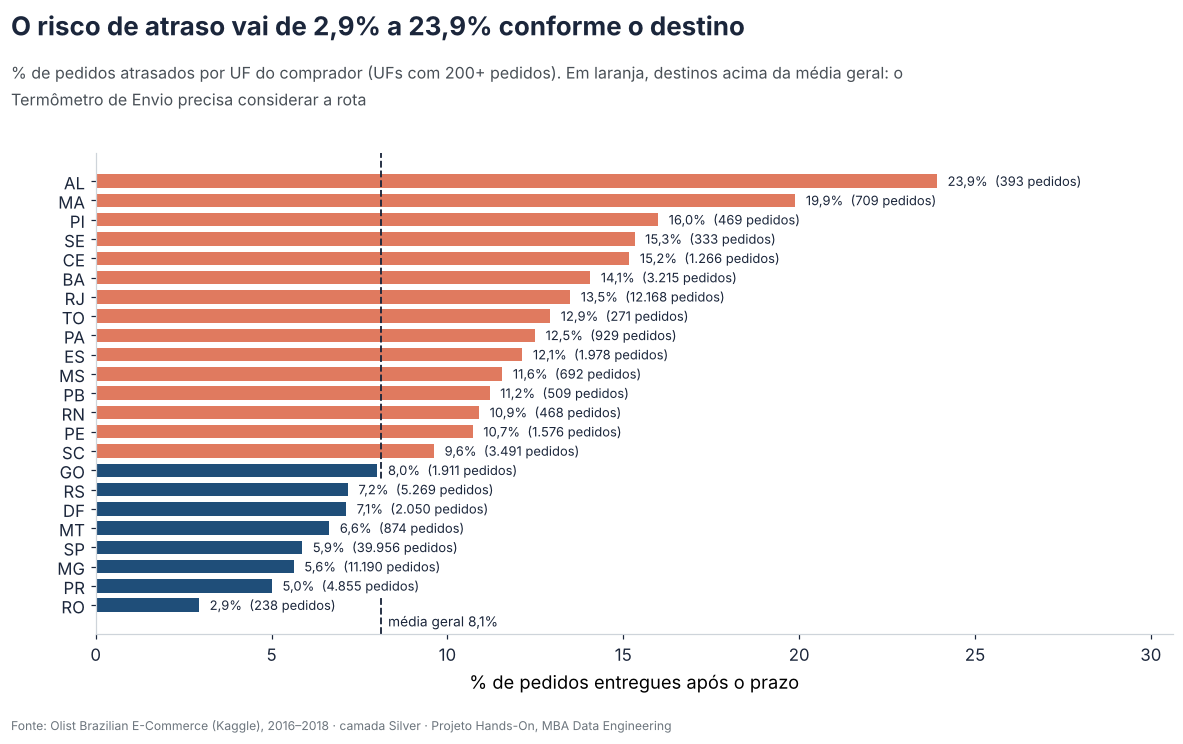

Gráfico salvo em: /home/claude/eda/img/grafico3_atraso_por_uf.png

✅ RESPOSTA (6. Onde e quando o atraso se concentra): As maiores taxas (UFs com 200+ pedidos) estão em AL (23,9%), MA (19,9%), PI (16,0%). Em volume, concentram os atrasos SP (30,4% dos atrasos com 42,0% dos pedidos), RJ (21,3% dos atrasos com 12,8% dos pedidos), MG (8,2% dos atrasos com 11,8% dos pedidos). Rotas mais críticas (1.000+ itens): SP → CE (14,9%, 20,8 dias), SP → RJ (14,9%, 16,1 dias), SP → BA (14,8%, 19,8 dias). Dentro do mesmo estado a entrega leva 7,9 dias e atrasa 6,0%; entre estados, 15,0 dias e 9,0%. Meses de maior atraso: 2018-03 (21,4%), 2018-02 (16,0%), 2017-11 (14,3%) (demais meses: 5,0% em média).


In [8]:
# ===== 6. ONDE E QUANDO O ATRASO SE CONCENTRA =====
uf = (df_deliv.join(df_m.select("order_id", "customer_state").dropDuplicates(["order_id"]), "order_id").groupBy("customer_state")
      .agg(F.count("*").alias("pedidos"), F.round(F.avg("delivery_time_days"), 2).alias("entrega_media"), F.round(F.avg("is_late") * 100, 2).alias("taxa_atraso_pct")))
u = uf.toPandas().sort_values("pedidos", ascending=False)
u["atrasados"] = u.pedidos * u.taxa_atraso_pct / 100
u["pct_dos_atrasos"] = u.atrasados / u.atrasados.sum() * 100
u["pct_dos_pedidos"] = u.pedidos / u.pedidos.sum() * 100
print("--- Atraso por UF do comprador ---"); display(u.round(2).reset_index(drop=True).head(15))

rp = (df_md.groupBy("route").agg(F.count("*").alias("itens"), F.round(F.avg("delivery_time_days"), 2).alias("entrega_media"), F.round(F.avg("is_late") * 100, 2).alias("taxa_atraso_pct"),
      F.round(F.avg("distance_km"), 0).alias("distancia_media_km")).toPandas())
crit = rp[rp.itens >= 1000].sort_values("taxa_atraso_pct", ascending=False)
print("--- Rotas com 1.000+ itens, das mais críticas ---"); display(crit.head(8).reset_index(drop=True))
ss = {int(r["same_state"]): r for r in df_md.groupBy("same_state").agg(F.round(F.avg("delivery_time_days"), 2).alias("entrega_media"), F.round(F.avg("is_late") * 100, 2).alias("taxa_atraso_pct")).collect()}
mes = df_deliv.groupBy("purchase_month").agg(F.count("*").alias("pedidos"), F.round(F.avg("is_late") * 100, 2).alias("taxa_atraso_pct")).toPandas()
mes = mes[mes.pedidos >= 100].sort_values("taxa_atraso_pct", ascending=False)
print("--- Meses com maior atraso ---"); display(mes.head(5).reset_index(drop=True))
media_geral = df_deliv.agg(F.avg("is_late")).first()[0] * 100

# ---- GRÁFICO 3: atraso por UF ----
gu = u[u.pedidos >= 200].sort_values("taxa_atraso_pct")
fig, ax = plt.subplots(figsize=(11, 7))
cores = [COR["laranja"] if v > media_geral else COR["azul"] for v in gu.taxa_atraso_pct]
ax.barh(gu.customer_state, gu.taxa_atraso_pct, color=cores, height=.7)
for yi, (v, n) in enumerate(zip(gu.taxa_atraso_pct, gu.pedidos)): ax.text(v + .3, yi, f"{br(v)}%  ({bi(n)} pedidos)", va="center", fontsize=8.5, color=COR["texto"], bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
ax.axvline(media_geral, color=COR["texto"], ls="--", lw=1.2); ax.text(media_geral + .2, -1.1, f"média geral {br(media_geral)}%", fontsize=9, color=COR["texto"])
ax.set_xlabel("% de pedidos entregues após o prazo"); ax.set_xlim(0, gu.taxa_atraso_pct.max() * 1.28); estilo_ax(ax); ax.grid(False)
salvar_grafico(fig, "grafico3_atraso_por_uf", f"O risco de atraso vai de {br(gu.taxa_atraso_pct.min())}% a {br(gu.taxa_atraso_pct.max())}% conforme o destino",
               "% de pedidos atrasados por UF do comprador (UFs com 200+ pedidos). Em laranja, destinos acima da média geral: o Termômetro de Envio precisa considerar a rota", "Termômetro de Envio")

alta = u[u.pedidos >= 200].sort_values("taxa_atraso_pct", ascending=False).head(3)
vol = u.sort_values("pct_dos_atrasos", ascending=False).head(3); top_m = mes.head(3); resto = mes.iloc[3:].taxa_atraso_pct.mean()
kp("atraso_uf_max", gu.taxa_atraso_pct.max()); kp("atraso_uf_min", gu.taxa_atraso_pct.min()); kp("atraso_mesmo_estado", ss[1]["taxa_atraso_pct"]); kp("atraso_entre_estados", ss[0]["taxa_atraso_pct"])
kp("entrega_mesmo_estado", ss[1]["entrega_media"]); kp("entrega_entre_estados", ss[0]["entrega_media"])
resp(6, "Onde e quando o atraso se concentra",
     "As maiores taxas (UFs com 200+ pedidos) estão em " + ", ".join(f"{a} ({br(t)}%)" for a, t in zip(alta.customer_state, alta.taxa_atraso_pct)) +
     ". Em volume, concentram os atrasos " + ", ".join(f"{a} ({br(p)}% dos atrasos com {br(d)}% dos pedidos)" for a, p, d in zip(vol.customer_state, vol.pct_dos_atrasos, vol.pct_dos_pedidos)) +
     ". Rotas mais críticas (1.000+ itens): " + ", ".join(f"{r.route} ({br(r.taxa_atraso_pct)}%, {br(r.entrega_media)} dias)" for r in crit.head(3).itertuples()) +
     f". Dentro do mesmo estado a entrega leva {br(ss[1]['entrega_media'])} dias e atrasa {br(ss[1]['taxa_atraso_pct'])}%; entre estados, {br(ss[0]['entrega_media'])} dias e {br(ss[0]['taxa_atraso_pct'])}%. "
     "Meses de maior atraso: " + ", ".join(f"{m} ({br(t)}%)" for m, t in zip(top_m.purchase_month, top_m.taxa_atraso_pct)) + f" (demais meses: {br(resto)}% em média).")

**Como interpretar**
- **Taxa × volume:** uma UF pode ter taxa de atraso alta e pouco volume (risco do destino) ou taxa moderada e muito volume (SP, RJ), que responde por grande parte dos atrasos. As duas leituras importam: a primeira para o aviso ao vendedor, a segunda para priorizar esforço.
- **Barras laranja** (acima da média) indicam destinos em que o vendedor deveria ajustar prazo ou modalidade de envio.
- O atraso se concentra em **poucos meses**: um modelo que ignora calendário e carga subestima o risco nesses períodos.

## 7. Sinais de atraso antes da postagem
**Pergunta:** Quais variáveis conhecidas antes da postagem separam os pedidos que atrasam dos que não atrasam?

**Uso no projeto:** Termômetro de Envio: define quais variáveis entram no modelo e quanto poder cada uma tem.

**O que o código faz:**
- Para cada variável (distância, prazo estimado, frete, peso, preço), divide os itens em 5 grupos de mesmo tamanho (**quintis**) e calcula a taxa de atraso em cada grupo.
- Compara a taxa do primeiro e do último quintil: quanto maior a diferença, mais a variável ajuda a separar os casos.
- Mostra a taxa de atraso por UF de origem do vendedor.

In [9]:
# ===== 7. SINAIS DE ATRASO ANTES DA POSTAGEM =====
y_ = df_md.agg(F.avg("is_late")).first()[0]
print(f"Classe positiva (item atrasado): {y_:.2%} → desbalanceamento de ~1:{1 / y_ - 1:.0f}")
def quintis(col):
    d = df_md.filter(F.col(col).isNotNull()).withColumn("quintil", F.ntile(5).over(Window.orderBy(col)))
    r = d.groupBy("quintil").agg(F.round(F.avg("is_late") * 100, 1).alias("taxa"), F.round(F.min(col), 1).alias("de"), F.round(F.max(col), 1).alias("ate")).orderBy("quintil").toPandas()
    return r
VARS = {"distance_km": "Distância (km)", "estimated_lead_days": "Prazo estimado (dias)", "freight_value": "Frete (R$)", "product_weight_g": "Peso (g)", "price": "Preço (R$)"}
linhas, amp = [], {}
for c, lbl in VARS.items():
    r = quintis(c); amp[lbl] = (r.taxa.iloc[0], r.taxa.iloc[-1])
    linhas.append({"variável": lbl, **{f"Q{int(q)}": f"{t:.1f}%" for q, t in zip(r.quintil, r.taxa)}, "faixa Q1 → Q5": f"{r.de.iloc[0]:,.0f} → {r.ate.iloc[-1]:,.0f}"})
qt = pd.DataFrame(linhas); display(qt)
orig = df_md.groupBy("seller_state").agg(F.count("*").alias("itens"), F.round(F.avg("is_late") * 100, 2).alias("taxa_atraso_pct")).filter("itens >= 300").orderBy(F.desc("taxa_atraso_pct"))
print("--- Atraso por UF de origem do vendedor (300+ itens) ---"); display(orig)
kp("taxa_item_atrasado_pct", y_ * 100)
resp(7, "Sinais de atraso antes da postagem",
     f"Existe sinal, mas moderado (só {br(y_ * 100)}% dos itens atrasam). Do 1º ao 5º quintil: distância {br(amp['Distância (km)'][0])}% → {br(amp['Distância (km)'][1])}%, frete {br(amp['Frete (R$)'][0])}% → {br(amp['Frete (R$)'][1])}%, "
     f"peso {br(amp['Peso (g)'][0])}% → {br(amp['Peso (g)'][1])}% e prazo estimado {br(amp['Prazo estimado (dias)'][0])}% → {br(amp['Prazo estimado (dias)'][1])}% (quanto maior a folga prometida, menor o atraso). "
     f"Rota, UF de origem e calendário completam o conjunto de variáveis do modelo.")

Classe positiva (item atrasado): 7.89% → desbalanceamento de ~1:12


26/11/13 22:50:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/11/13 22:50:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:22 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:23 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/11/13 22:50:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/13 22:50:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


... (3 outputs left out)

,variável,Q1,Q2,Q3,Q4,Q5,faixa Q1 → Q5
0,Distância (km),6.5%,6.6%,7.2%,8.3%,10.8%,"0 → 3,398"
1,Prazo estimado (dias),8.6%,9.2%,8.6%,7.9%,5.1%,2 → 155
2,Frete (R$),5.9%,6.4%,8.8%,8.7%,9.6%,0 → 410
3,Peso (g),7.4%,7.6%,7.4%,8.3%,8.7%,"0 → 40,425"
4,Preço (R$),7.3%,7.4%,7.8%,8.0%,9.1%,"1 → 6,735"


--- Atraso por UF de origem do vendedor (300+ itens) ---


,seller_state,itens,taxa_atraso_pct
0,MA,402,23.63
1,SP,77494,8.49
2,RJ,4603,8.04
3,DF,873,6.76
4,PR,8431,6.48
5,ES,357,5.88
6,SC,3981,5.85
7,MG,8400,5.61
8,BA,624,5.45
9,RS,2123,4.57



✅ RESPOSTA (7. Sinais de atraso antes da postagem): Existe sinal, mas moderado (só 7,9% dos itens atrasam). Do 1º ao 5º quintil: distância 6,5% → 10,8%, frete 5,9% → 9,6%, peso 7,4% → 8,7% e prazo estimado 8,6% → 5,1% (quanto maior a folga prometida, menor o atraso). Rota, UF de origem e calendário completam o conjunto de variáveis do modelo.


**Como interpretar**
- **Leia cada linha da esquerda para a direita (Q1 → Q5):** se a taxa sobe, a variável aumenta o risco; se desce (como o prazo estimado), a variável protege.
- Variáveis com **maior diferença entre Q1 e Q5** têm mais poder de separação e são boas candidatas ao modelo.
- Nenhuma variável sozinha separa bem: o ganho do modelo vem da **combinação** (rota + distância + prazo + calendário). Por isso o resultado esperado do modelo é moderado, e deve ser comunicado como probabilidade, não como certeza.

## 8. Atraso e reputação
**Pergunta:** O atraso derruba a nota que o cliente dá ao vendedor?

**Uso no projeto:** Diagnóstico 360° (peso da logística na Nota de Saúde) e Termômetro de Envio (o que está em jogo ao atrasar).

**O que o código faz:**
- Compara nota média e % de notas 1–2 entre pedidos atrasados e no prazo.
- Agrupa os pedidos por faixa de **tempo de entrega** e mede a nota em cada uma; calcula a correlação da nota com o tempo de entrega.
- **Gera o Gráfico 4** (nota média por faixa de tempo de entrega).

,grupo,pedidos,nota_media,pct_notas_1_2
0,no prazo,88163,4.29,9.22
1,atrasado,7661,2.57,54.07


,faixa,pedidos,nota_media,pct_notas_1_2
0,Até 7 dias,25933,4.42,7.40
1,8–14 dias,39997,4.31,9.00
2,15–21 dias,17582,4.14,11.70
3,22–30 dias,7882,3.61,24.30
4,Mais de 30 dias,4430,2.25,63.00


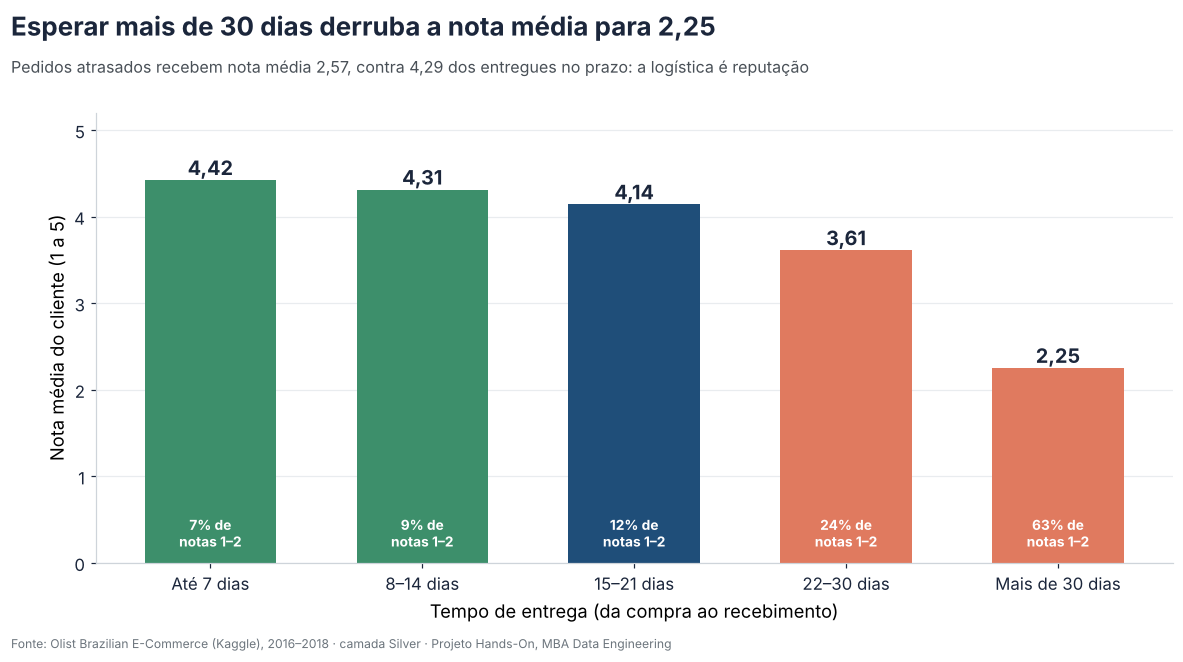

Gráfico salvo em: /home/claude/eda/img/grafico4_nota_tempo_entrega.png

✅ RESPOSTA (8. Atraso e reputação): Pedidos atrasados recebem nota média 2,57 contra 4,29 no prazo, e 54,1% deles são notas 1–2 (no prazo: 9,2%). A nota cai com a espera: 4,42 até 7 dias contra 2,25 acima de 30 dias (63,0% de notas 1–2). Correlação da nota com o tempo de entrega: -0,33; com os dias de atraso: -0,27.


In [10]:
# ===== 8. ATRASO E REPUTAÇÃO =====
lt = {int(r["is_late"]): r for r in df_dr.groupBy("is_late").agg(F.count("*").alias("pedidos"), F.round(F.avg("review_score"), 2).alias("nota_media"),
      F.round(pct(F.col("review_score") <= 2), 2).alias("pct_notas_1_2")).collect()}
display(pd.DataFrame({"grupo": ["no prazo", "atrasado"], "pedidos": [lt[0]["pedidos"], lt[1]["pedidos"]], "nota_media": [lt[0]["nota_media"], lt[1]["nota_media"]],
                      "pct_notas_1_2": [lt[0]["pct_notas_1_2"], lt[1]["pct_notas_1_2"]]}))
faixa_t = (F.when(F.col("delivery_time_days") <= 7, "1. Até 7 dias").when(F.col("delivery_time_days") <= 14, "2. 8–14 dias").when(F.col("delivery_time_days") <= 21, "3. 15–21 dias")
            .when(F.col("delivery_time_days") <= 30, "4. 22–30 dias").otherwise("5. Mais de 30 dias"))
nt = (df_dr.groupBy(faixa_t.alias("faixa")).agg(F.count("*").alias("pedidos"), F.round(F.avg("review_score"), 2).alias("nota_media"),
      F.round(pct(F.col("review_score") <= 2), 1).alias("pct_notas_1_2")).orderBy("faixa").toPandas())
nt["faixa"] = nt.faixa.str[3:]
display(nt)
c1, c2 = df_dr.stat.corr("review_score", "delivery_time_days"), df_dr.stat.corr("review_score", "delivery_delay_days")

# ---- GRÁFICO 4: nota × tempo de entrega ----
fig, ax = plt.subplots(figsize=(11, 6.2))
cores = [COR["verde"], COR["verde"], COR["azul"], COR["laranja"], COR["laranja"]]
b = ax.bar(nt.faixa, nt.nota_media, color=cores, width=.62)
for rect, v, p in zip(b, nt.nota_media, nt.pct_notas_1_2):
    ax.text(rect.get_x() + rect.get_width() / 2, v + .06, f"{br(v, 2)}", ha="center", fontsize=13, fontweight="bold", color=COR["texto"])
    ax.text(rect.get_x() + rect.get_width() / 2, .15, f"{br(p, 0)}% de\nnotas 1–2", ha="center", va="bottom", fontsize=9, color="white", fontweight="bold")
ax.set_ylim(0, 5.2); ax.set_ylabel("Nota média do cliente (1 a 5)"); ax.set_xlabel("Tempo de entrega (da compra ao recebimento)"); estilo_ax(ax)
salvar_grafico(fig, "grafico4_nota_tempo_entrega", f"Esperar mais de 30 dias derruba a nota média para {br(nt.nota_media.iloc[-1], 2)}",
               f"Pedidos atrasados recebem nota média {br(lt[1]['nota_media'], 2)}, contra {br(lt[0]['nota_media'], 2)} dos entregues no prazo: a logística é reputação", "Diagnóstico 360° · reputação")
for k, v in {"nota_atrasados": lt[1]["nota_media"], "nota_no_prazo": lt[0]["nota_media"], "pct_notas12_atrasados": lt[1]["pct_notas_1_2"], "pct_notas12_no_prazo": lt[0]["pct_notas_1_2"],
             "nota_gt30": nt.nota_media.iloc[-1], "pct_notas12_gt30": nt.pct_notas_1_2.iloc[-1], "nota_ate7": nt.nota_media.iloc[0], "corr_nota_tempo": c1}.items(): kp(k, v)
resp(8, "Atraso e reputação",
     f"Pedidos atrasados recebem nota média {br(lt[1]['nota_media'], 2)} contra {br(lt[0]['nota_media'], 2)} no prazo, e {br(lt[1]['pct_notas_1_2'])}% deles são notas 1–2 (no prazo: {br(lt[0]['pct_notas_1_2'])}%). "
     f"A nota cai com a espera: {br(nt.nota_media.iloc[0], 2)} até 7 dias contra {br(nt.nota_media.iloc[-1], 2)} acima de 30 dias ({br(nt.pct_notas_1_2.iloc[-1])}% de notas 1–2). Correlação da nota com o tempo de entrega: {br(c1, 2)}; com os dias de atraso: {br(c2, 2)}.")

**Como interpretar**
- **Degrau na nota:** até 21 dias a nota fica acima de 4; de 22 a 30 dias ela cai de forma clara, e acima de 30 dias o cliente tende a dar nota 1 ou 2.
- A correlação negativa (perto de −0,3) é **moderada**: o tempo não explica tudo, mas é o fator logístico mais ligado à insatisfação.
- Para o vendedor, evitar o atraso protege a reputação (e a posição no marketplace); por isso o Termômetro de Envio e a dimensão de logística da Nota de Saúde têm peso relevante.

## 9. Concentração do atraso entre vendedores
**Pergunta:** O atraso está espalhado ou concentrado em poucos vendedores, e a logística do vendedor explica a nota dele?

**Uso no projeto:** Diagnóstico 360°: mostra o espaço de melhoria por vendedor e valida a logística como dimensão da Nota de Saúde.

**O que o código faz:**
- Calcula, por vendedor, pedidos, receita, taxa de atraso, tempo de postagem, entrega, nota e frete sobre preço.
- Entre os vendedores com **10+ pedidos** (base mínima para comparar), mostra a distribuição da taxa de atraso e quanto dos itens atrasados vem dos vendedores com taxa de 15% ou mais.
- Calcula a concentração de receita (top 10% dos vendedores) e as correlações entre indicadores.

In [11]:
# ===== 9. CONCENTRAÇÃO DO ATRASO ENTRE VENDEDORES =====
cat_cnt = df_md.groupBy("seller_id", "category").count()
cat_main = (cat_cnt.withColumn("rn", F.row_number().over(Window.partitionBy("seller_id").orderBy(F.desc("count"), "category"))).filter("rn = 1")
            .select("seller_id", F.col("category").alias("categoria_principal")))
df_sm = (df_md.groupBy("seller_id").agg(F.countDistinct("order_id").alias("pedidos"), F.sum("price").alias("receita"), F.avg("is_late").alias("taxa_atraso"),
          F.sum("is_late").alias("itens_atrasados"), F.avg("handling_time_days").alias("postagem_media"), F.avg("delivery_time_days").alias("entrega_media"),
          F.avg("review_score").alias("nota_media"), F.expr("percentile_approx(frete_pct, 0.5)").alias("frete_pct_mediano"), F.first("seller_state").alias("uf"))
         .join(cat_main, "seller_id", "left").cache())
sm = df_sm.toPandas(); el = sm[sm.pedidos >= 10].copy()
rv = sm.receita.sort_values(ascending=False).values; top10 = rv[:int(len(rv) * .1)].sum() / rv.sum()
print(f"Vendedores com entregas: {len(sm):,} | mediana de pedidos: {sm.pedidos.median():.0f} | 10+ pedidos: {len(el):,} ({len(el) / len(sm):.0%}) | top 10% = {top10:.1%} da receita")
q = el.taxa_atraso.quantile([.25, .5, .75, .9]) * 100
print("Taxa de atraso dos vendedores com 10+ pedidos (P25 / mediana / P75 / P90): " + " / ".join(f"{v:.1f}%" for v in q))
ruim = el[el.taxa_atraso >= 0.15]; share_ruim = ruim.itens_atrasados.sum() / el.itens_atrasados.sum()
faixas = pd.cut(el.taxa_atraso * 100, [-0.1, 5, 10, 15, 25, 100], labels=["≤5%", "5–10%", "10–15%", "15–25%", ">25%"])
display(el.groupby(faixas).agg(vendedores=("seller_id", "size"), nota_mediana=("nota_media", "median"), postagem_mediana=("postagem_media", "median")).round(2))
cm = el[["taxa_atraso", "postagem_media", "entrega_media", "frete_pct_mediano", "nota_media", "receita"]].corr(method="spearman")
display(cm.round(2))
for k, v in {"vendedores_total": len(sm), "vendedores_ge10": len(el), "mediana_pedidos_vendedor": sm.pedidos.median(), "top10_vendedores_pct_receita": top10 * 100, "atraso_mediano_vendedor": q[.5],
             "pct_vendedores_atraso_ge15": len(ruim) / len(el) * 100, "share_atrasos_vendedores_ge15": share_ruim * 100, "corr_atraso_nota_vendedor": cm.loc["taxa_atraso", "nota_media"]}.items(): kp(k, v)
resp(9, "Concentração do atraso entre vendedores",
     f"A base é pequena e desigual: {bi(len(sm))} vendedores com entregas, mediana de {sm.pedidos.median():.0f} pedidos; só {bi(len(el))} ({br(len(el) / len(sm) * 100, 0)}%) têm 10+ e os 10% maiores concentram {br(top10 * 100)}% da receita. "
     f"Entre os que têm 10+ pedidos, a taxa de atraso mediana é {br(q[.5])}% e 25% passam de {br(q[.75])}%; os {bi(len(ruim))} vendedores com taxa de 15% ou mais ({br(len(ruim) / len(el) * 100)}% do grupo) respondem por {br(share_ruim * 100)}% dos itens atrasados. "
     f"A taxa de atraso do vendedor tem correlação {br(cm.loc['taxa_atraso', 'nota_media'], 2)} com a nota média dele e {br(cm.loc['taxa_atraso', 'postagem_media'], 2)} com o tempo de postagem.")

Vendedores com entregas: 2,914 | mediana de pedidos: 7 | 10+ pedidos: 1,217 (42%) | top 10% = 67.0% da receita
Taxa de atraso dos vendedores com 10+ pedidos (P25 / mediana / P75 / P90): 2.6% / 6.4% / 11.0% / 16.7%


,vendedores,nota_mediana,postagem_mediana
taxa_atraso,,,
≤5%,493,4.32,2.27
5–10%,382,4.18,2.49
10–15%,185,4.04,2.95
15–25%,121,3.94,3.47
>25%,36,3.56,4.95


,taxa_atraso,postagem_media,entrega_media,frete_pct_mediano,nota_media,receita
taxa_atraso,1.00,0.28,0.48,-0.02,-0.37,0.10
postagem_media,0.28,1.00,0.62,-0.04,-0.39,0.11
entrega_media,0.48,0.62,1.00,-0.08,-0.44,0.23
frete_pct_mediano,-0.02,-0.04,-0.08,1.00,-0.08,-0.46
nota_media,-0.37,-0.39,-0.44,-0.08,1.00,-0.13
receita,0.10,0.11,0.23,-0.46,-0.13,1.00



✅ RESPOSTA (9. Concentração do atraso entre vendedores): A base é pequena e desigual: 2.914 vendedores com entregas, mediana de 7 pedidos; só 1.217 (42%) têm 10+ e os 10% maiores concentram 67,0% da receita. Entre os que têm 10+ pedidos, a taxa de atraso mediana é 6,4% e 25% passam de 11,0%; os 161 vendedores com taxa de 15% ou mais (13,2% do grupo) respondem por 17,5% dos itens atrasados. A taxa de atraso do vendedor tem correlação -0,37 com a nota média dele e 0,28 com o tempo de postagem.


**Como interpretar**
- **Mediana de pedidos baixa** mostra que o público-alvo (vendedor pequeno) é a regra, e que um benchmark só faz sentido com **volume mínimo**.
- Se uma fatia pequena dos vendedores gera uma fatia maior dos atrasos, o diagnóstico tem **espaço de melhoria claro**: priorizar quem está acima do benchmark.
- A tabela por faixa de atraso mostra a nota caindo à medida que o atraso sobe; a correlação **negativa** entre atraso e nota do vendedor sustenta a logística como dimensão da Nota de Saúde.

## 10. Benchmark dos melhores lojistas
**Pergunta:** Há volume para comparar cada vendedor com os melhores da categoria e em que os melhores se diferenciam?

**Uso no projeto:** Diagnóstico 360°: define a base do benchmark e quais indicadores entram como lacuna e ação prioritária.

**O que o código faz:**
- Conta vendedores elegíveis (10+ pedidos) por categoria principal e quantas categorias têm **massa crítica** (5+ ou 10+ elegíveis).
- Define os **melhores** (receita no quartil superior e nota média ≥ 4) e compara as **medianas** de atraso, postagem, entrega, frete sobre preço e nota com os demais.

In [12]:
# ===== 10. BENCHMARK DOS MELHORES LOJISTAS =====
cc_ = el.groupby("categoria_principal").size().sort_values(ascending=False)
n5, n10 = int((cc_ >= 5).sum()), int((cc_ >= 10).sum()); cob5 = cc_[cc_ >= 5].sum() / len(el)
print(f"Vendedores elegíveis: {len(el):,} em {len(cc_)} categorias | com 5+ elegíveis: {n5} categorias | com 10+: {n10}")
display(cc_.head(10).to_frame("vendedores elegíveis").T)
el["grupo"] = np.where((el.receita >= el.receita.quantile(.75)) & (el.nota_media >= 4), "melhores", "demais")
mets = ["pedidos", "taxa_atraso", "postagem_media", "entrega_media", "frete_pct_mediano", "nota_media"]
cmp_ = el.groupby("grupo")[mets].median().T
cmp_["diferença %"] = (cmp_["melhores"] / cmp_["demais"] - 1) * 100
display(cmp_.round(3))
nm = int((el.grupo == "melhores").sum())
print(f"Vendedores: melhores = {nm} | demais = {len(el) - nm}\nAtenção: receita e nota definem o grupo; os demais indicadores são associações, não causas.")
for k, v in {"categorias_massa_critica_5": n5, "categorias_massa_critica_10": n10, "cobertura_massa_critica_pct": cob5 * 100, "melhores_lojistas": nm,
             "frete_pct_melhores": cmp_.loc["frete_pct_mediano", "melhores"], "frete_pct_demais": cmp_.loc["frete_pct_mediano", "demais"],
             "atraso_melhores_pct": cmp_.loc["taxa_atraso", "melhores"] * 100, "atraso_demais_pct": cmp_.loc["taxa_atraso", "demais"] * 100}.items(): kp(k, v)
resp(10, "Benchmark dos melhores lojistas",
     f"Há massa crítica para benchmark (5+ vendedores com 10+ pedidos) em {n5} categorias, que cobrem {br(cob5 * 100, 0)}% dos vendedores elegíveis. Os {nm} melhores lojistas não se destacam em velocidade logística: "
     f"taxa de atraso mediana de {br(cmp_.loc['taxa_atraso', 'melhores'] * 100)}% contra {br(cmp_.loc['taxa_atraso', 'demais'] * 100)}%, postagem de {br(cmp_.loc['postagem_media', 'melhores'])} contra {br(cmp_.loc['postagem_media', 'demais'])} dias "
     f"e entrega de {br(cmp_.loc['entrega_media', 'melhores'])} contra {br(cmp_.loc['entrega_media', 'demais'])} dias; a diferença está no frete mais leve no preço ({br(cmp_.loc['frete_pct_mediano', 'melhores'])}% contra {br(cmp_.loc['frete_pct_mediano', 'demais'])}%).")

Vendedores elegíveis: 1,217 em 62 categorias | com 5+ elegíveis: 32 categorias | com 10+: 23


categoria_principal,sports_leisure,health_beauty,housewares,furniture_decor,computers_accessories,auto,bed_bath_table,toys,baby,telephony
vendedores elegíveis,129,129,104,87,74,68,67,60,40,35


grupo,demais,melhores,diferença %
pedidos,24.00,112.50,368.75
taxa_atraso,0.07,0.06,-11.06
postagem_media,2.55,2.57,0.90
entrega_media,11.66,12.00,2.93
frete_pct_mediano,23.55,15.41,-34.54
nota_media,4.16,4.26,2.48


Vendedores: melhores = 208 | demais = 1009
Atenção: receita e nota definem o grupo; os demais indicadores são associações, não causas.

✅ RESPOSTA (10. Benchmark dos melhores lojistas): Há massa crítica para benchmark (5+ vendedores com 10+ pedidos) em 32 categorias, que cobrem 95% dos vendedores elegíveis. Os 208 melhores lojistas não se destacam em velocidade logística: taxa de atraso mediana de 5,9% contra 6,7%, postagem de 2,6 contra 2,5 dias e entrega de 12,0 contra 11,7 dias; a diferença está no frete mais leve no preço (15,4% contra 23,5%).


**Como interpretar**
- **Massa crítica:** só vale comparar o vendedor com o benchmark de categorias com vendedores suficientes; nas demais, use um agrupamento de categorias ou a referência nacional.
- Em **`diferença %`**, valores perto de zero (atraso, postagem, entrega) indicam que os melhores não são diferentes nesses pontos; valores grandes indicam onde estão as diferenças.
- Receita e nota **definem** o grupo; portanto as diferenças nos outros indicadores são **associações**. O relatório deve tratar o ganho como **potencial estimado**, não como garantia.

## 11. Quadro-resumo e exportação para a apresentação
**O que o código faz:** reúne as 10 respostas em uma tabela e **exporta** as respostas, os indicadores (`KPIS`) e a lista dos 4 gráficos para `insights_eda.json`, na mesma pasta dos PNG (`IMG_DIR`). Esse arquivo alimenta o relatório HTML de insights.

In [13]:
resumo = pd.DataFrame([(n, t, txt) for n, (t, txt) in sorted(RESPOSTAS.items())], columns=["#", "Tema", "Resposta"])
pd.set_option("display.max_colwidth", None)
display(resumo)
payload = {"respostas": {str(n): {"tema": t, "texto": txt} for n, (t, txt) in sorted(RESPOSTAS.items())},
           "kpis": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in KPIS.items()}, "graficos": GRAFICOS}
with open(f"{IMG_DIR}/insights_eda.json", "w", encoding="utf-8") as f: json.dump(payload, f, ensure_ascii=False, indent=2)
print(f"Exportado: {IMG_DIR}/insights_eda.json | gráficos: {', '.join(g['arquivo'] for g in GRAFICOS.values())}")

,#,Tema,Resposta
0,1,Tamanho do mercado,"O mercado analisado soma 95.138 pedidos entregues, R$ 13.049.522 em receita e 2.914 vendedores ativos em 73 categorias. As 10 maiores categorias respondem por 63,2% da receita (líder: health_beauty, 9,4%) e as 3 maiores UFs (SP, RJ, MG) por 66,5% dos pedidos."
1,2,Oferta × demanda por UF,"SP tem 42,0% da demanda e 70,7% da oferta. UFs com muita demanda e poucos vendedores locais: BA (179 pedidos por vendedor local), PE (175 pedidos por vendedor local), CE (106 pedidos por vendedor local). 5 UFs não têm nenhum vendedor com entregas na base."
2,3,Saturação por categoria,"Mais saturadas (poucos pedidos por vendedor): construction_tools_construction (6,0), small_appliances (6,3), home_construction (7,2). Mais oportunas (muitos pedidos por vendedor): watches_gifts (57,8), bed_bath_table (49,1), office_furniture (41,8)."
3,4,Peso do frete no preço,"O frete pesa mais quanto mais barato o item: a mediana é 73,2% do preço até R$ 25, 37,7% entre R$ 25 e 50 e 3,8% acima de R$ 500; 36,6% de todos os itens têm frete igual ou maior que 30% do preço. O frete acompanha o peso (correlação 0,61), o preço (0,41) e a distância (0,39)."
4,5,Prazo prometido × entregue,"8,11% dos pedidos entregues chegam depois do prazo. A entrega leva em média 12,6 dias (mediana 10,2; 90% até 23,1) contra 23,7 prometidos, folga média de 11,2 dias. Quando atrasa, o atraso médio é de 9,6 dias. O atraso é um evento raro e de impacto grande."
5,6,Onde e quando o atraso se concentra,"As maiores taxas (UFs com 200+ pedidos) estão em AL (23,9%), MA (19,9%), PI (16,0%). Em volume, concentram os atrasos SP (30,4% dos atrasos com 42,0% dos pedidos), RJ (21,3% dos atrasos com 12,8% dos pedidos), MG (8,2% dos atrasos com 11,8% dos pedidos). Rotas mais críticas (1.000+ itens): SP → CE (14,9%, 20,8 dias), SP → RJ (14,9%, 16,1 dias), SP → BA (14,8%, 19,8 dias). Dentro do mesmo estado a entrega leva 7,9 dias e atrasa 6,0%; entre estados, 15,0 dias e 9,0%. Meses de maior atraso: 2018-03 (21,4%), 2018-02 (16,0%), 2017-11 (14,3%) (demais meses: 5,0% em média)."
6,7,Sinais de atraso antes da postagem,"Existe sinal, mas moderado (só 7,9% dos itens atrasam). Do 1º ao 5º quintil: distância 6,5% → 10,8%, frete 5,9% → 9,6%, peso 7,4% → 8,7% e prazo estimado 8,6% → 5,1% (quanto maior a folga prometida, menor o atraso). Rota, UF de origem e calendário completam o conjunto de variáveis do modelo."
7,8,Atraso e reputação,"Pedidos atrasados recebem nota média 2,57 contra 4,29 no prazo, e 54,1% deles são notas 1–2 (no prazo: 9,2%). A nota cai com a espera: 4,42 até 7 dias contra 2,25 acima de 30 dias (63,0% de notas 1–2). Correlação da nota com o tempo de entrega: -0,33; com os dias de atraso: -0,27."
8,9,Concentração do atraso entre vendedores,"A base é pequena e desigual: 2.914 vendedores com entregas, mediana de 7 pedidos; só 1.217 (42%) têm 10+ e os 10% maiores concentram 67,0% da receita. Entre os que têm 10+ pedidos, a taxa de atraso mediana é 6,4% e 25% passam de 11,0%; os 161 vendedores com taxa de 15% ou mais (13,2% do grupo) respondem por 17,5% dos itens atrasados. A taxa de atraso do vendedor tem correlação -0,37 com a nota média dele e 0,28 com o tempo de postagem."
9,10,Benchmark dos melhores lojistas,"Há massa crítica para benchmark (5+ vendedores com 10+ pedidos) em 32 categorias, que cobrem 95% dos vendedores elegíveis. Os 208 melhores lojistas não se destacam em velocidade logística: taxa de atraso mediana de 5,9% contra 6,7%, postagem de 2,6 contra 2,5 dias e entrega de 12,0 contra 11,7 dias; a diferença está no frete mais leve no preço (15,4% contra 23,5%)."


Exportado: /home/claude/eda/img/insights_eda.json | gráficos: grafico1_demanda_oferta.png, grafico2_frete_preco.png, grafico3_atraso_por_uf.png, grafico4_nota_tempo_entrega.png


## 12. Implicações para o projeto
- **Radar de Oportunidades:** apresentar demanda e oferta por UF e categoria **junto do custo logístico** (frete sobre preço, prazo e atraso do destino); demanda pouco atendida só é oportunidade se o custo de chegar lá for viável.
- **Termômetro de Envio:** o atraso é raro, concentrado em poucas rotas e meses e de impacto grande na nota. Use rota, distância, folga do prazo, frete, peso e calendário; avalie por PR-AUC e recall (classes desbalanceadas) e comunique a saída como probabilidade.
- **Diagnóstico 360°:** a logística entra na Nota de Saúde com peso relevante; benchmark só com vendedores de 10+ pedidos e categorias com massa crítica; as "3 ações" priorizam atraso nas rotas críticas, preço e frete de itens baratos e qualidade do catálogo, tratando o ganho como potencial estimado.